# Olist E-Commerce: Which Orders Get Bad Reviews?

**Main question:** which orders are likely to be delivered late or get a bad review (1-2 stars), and what causes it?

**Data:** [Brazilian E-Commerce Public Dataset by Olist](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce) (about 100k orders, 2016-2018, 9 related tables).

**What this notebook does:**
1. Load the data
2. Check the data
3. Delivered orders, delivery time and late orders
4. Reviews and the "bad review" label
5. Build one table with one row per order
6. Clean the data and create features
7. Analysis by state
8. Delivery time, promise and reviews
9. Other patterns (several items or sellers, months)
10. Preparing the data for machine learning
11. Models
12. Experiments (late-delivery information, month, time-based split, risk groups, simple rule)
13. What do the review messages say?
14. Export for Power BI
15. Key findings and limitations

In [1]:
# Libraries
import os
import pandas as pd
import matplotlib.pyplot as plt

# Machine learning tools
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    classification_report, roc_auc_score,
)

# Folder for the charts we save (it is created if it does not exist)
os.makedirs("images", exist_ok=True)

## 1. Loading the data

The CSV files are in the `data` folder. First we check that all 9 files are there and look at their size (rows, columns).

In [2]:
# Go through every CSV file in the data folder and print its shape (rows, columns)
# The geolocation file has about 1 million rows, so this cell can take a moment
for name in os.listdir("data"):
    if name.endswith(".csv"):
        df = pd.read_csv("data/" + name)
        print(name, df.shape)

olist_customers_dataset.csv (99441, 5)
olist_geolocation_dataset.csv (1000163, 5)
olist_orders_dataset.csv (99441, 8)
olist_order_items_dataset.csv (112650, 7)
olist_order_payments_dataset.csv (103886, 5)
olist_order_reviews_dataset.csv (99224, 7)
olist_products_dataset.csv (32951, 9)
olist_sellers_dataset.csv (3095, 4)
product_category_name_translation.csv (71, 2)


In [3]:
# Load each table into its own variable
# (the geolocation file is not needed yet, so we skip it)
customers = pd.read_csv("data/olist_customers_dataset.csv")
orders = pd.read_csv("data/olist_orders_dataset.csv")
items = pd.read_csv("data/olist_order_items_dataset.csv")
payments = pd.read_csv("data/olist_order_payments_dataset.csv")
reviews = pd.read_csv("data/olist_order_reviews_dataset.csv")
products = pd.read_csv("data/olist_products_dataset.csv")
sellers = pd.read_csv("data/olist_sellers_dataset.csv")
translation = pd.read_csv("data/product_category_name_translation.csv")

## 2. Checking the data

We look at missing values and at the order status. The order status tells us which orders actually reached the customer.

In [4]:
# How many missing (empty) values are in each column?
print("Orders:")
print(orders.isnull().sum())

print("Reviews:")
print(reviews.isnull().sum())

print("Products:")
print(products.isnull().sum())

Orders:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64
Reviews:
review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64
Products:
product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64


In [5]:
# How many orders have each status (delivered, canceled, shipped, ...)?
print(orders["order_status"].value_counts())

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


In [6]:
# Which statuses do the orders without a delivery date have?
# Most of them were never delivered, so a missing date makes sense
missing_delivery = orders[orders["order_delivered_customer_date"].isnull()]
print(missing_delivery["order_status"].value_counts())

order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64


## 3. Delivered orders, delivery time and late orders

We can only measure delivery time and lateness for orders that were delivered, so we keep those in a separate table called `delivered`. The `orders` table stays unchanged.

In [7]:
# Turn the date columns from text into real dates, so we can subtract them
date_columns = [
    "order_purchase_timestamp",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]

for col in date_columns:
    orders[col] = pd.to_datetime(orders[col])

In [8]:
# Keep only delivered orders that have a delivery date
delivered = orders[
    (orders["order_status"] == "delivered")
    & (orders["order_delivered_customer_date"].notnull())
].copy()

print(len(delivered))

96470


In [9]:
# delivery_days = days from purchase to delivery
delivered["delivery_days"] = (
    delivered["order_delivered_customer_date"]
    - delivered["order_purchase_timestamp"]
).dt.days

# is_late = 1 if the order arrived after the estimated delivery date, otherwise 0
delivered["is_late"] = (
    delivered["order_delivered_customer_date"]
    > delivered["order_estimated_delivery_date"]
).astype(int)

print(delivered["delivery_days"].describe())

# Share of late orders (about 8%)
print(delivered["is_late"].mean())

count    96470.000000
mean        12.093604
std          9.551380
min          0.000000
25%          6.000000
50%         10.000000
75%         15.000000
max        209.000000
Name: delivery_days, dtype: float64
0.08112366538820359


In [10]:
# How many orders have extreme delivery times?
# Over 60 days: very slow. Exactly 0 days: delivered within 24 hours.
# They are rare, so we keep them.
print((delivered["delivery_days"] > 60).sum())
print((delivered["delivery_days"] == 0).sum())

288
13


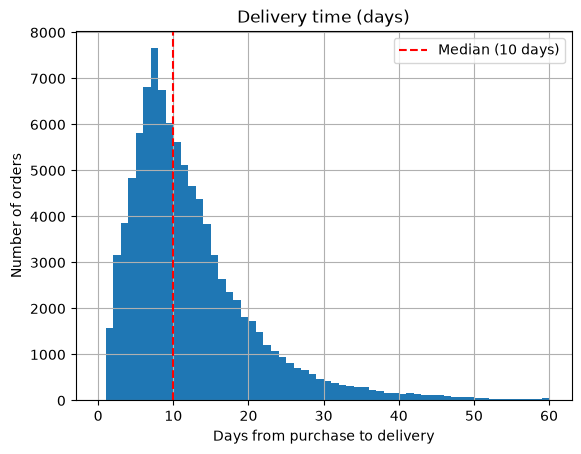

In [11]:
# Histogram of delivery time (one bar per day, zoomed to 0-60 days)
delivered["delivery_days"].hist(bins=range(0, 61))
plt.title("Delivery time (days)")
plt.xlabel("Days from purchase to delivery")
plt.ylabel("Number of orders")
plt.axvline(delivered["delivery_days"].median(), color="red", linestyle="--", label="Median (10 days)")
plt.legend()

# savefig must come BEFORE show, otherwise the saved image is empty
plt.savefig("images/delivery_time_histogram.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Reviews and the "bad review" label

Some orders have more than one review, so we keep only the latest review of each order. Then we create the label we want to predict: `bad_review` = 1 if the score is 1 or 2.

In [12]:
# Are there orders with more than one review?
print(reviews["order_id"].duplicated().sum())

# Keep only one review per order (the latest one)
reviews["review_answer_timestamp"] = pd.to_datetime(reviews["review_answer_timestamp"])

reviews_clean = reviews.sort_values("review_answer_timestamp").drop_duplicates(
    subset="order_id", keep="last"
)
print(len(reviews_clean))

551
98673


In [13]:
# Add the review score to each delivered order
# how="left" keeps all delivered orders, even those without a review
data = delivered.merge(
    reviews_clean[["order_id", "review_score"]],
    on="order_id",
    how="left",
)

# Do late orders get lower review scores?
print(data.groupby("is_late")["review_score"].mean())

is_late
0    4.294114
1    2.565070
Name: review_score, dtype: float64


In [14]:
# Delete the orders that have no review score
data_reviewed = data[data["review_score"].notnull()].copy()
print(len(data_reviewed))

# bad_review = 1 when the score is 1 or 2, otherwise 0
data_reviewed["bad_review"] = (data_reviewed["review_score"] <= 2).astype(int)

95824


In [15]:
# Distribution of the review scores, the share of bad reviews,
# and the bad review rate for on-time (0) and late (1) orders
print(data_reviewed["review_score"].value_counts(normalize=True).sort_index())
print(data_reviewed["bad_review"].mean())
print(data_reviewed.groupby("is_late")["bad_review"].mean())
print(data_reviewed["is_late"].value_counts())

review_score
1.0    0.097585
2.0    0.030483
3.0    0.082610
4.0    0.197111
5.0    0.592211
Name: proportion, dtype: float64
0.128068124895642
is_late
0    0.092216
1    0.540660
Name: bad_review, dtype: float64
is_late
0    88163
1     7661
Name: count, dtype: int64


## 5. One table with one row per order

The items table has several rows per order, so we summarize it first. Then we add the customer state, the product details and the seller state.

In [16]:
# Number of rows in the items table (more than the number of orders)
print(len(items))

112650


In [17]:
# One row per order: total price, total freight, number of items, number of different sellers
items_per_order = items.groupby("order_id").agg(
    total_price=("price", "sum"),
    total_freight=("freight_value", "sum"),
    item_count=("order_item_id", "count"),
    seller_count=("seller_id", "nunique"),
).reset_index()

print(len(items_per_order))

98666


In [18]:
# NOTE: the merge cells in this section add columns to data_reviewed.
# Run them only once. If you need to run them again, use Kernel -> Restart & Run All.

# Add the item summary to each order
data_reviewed = data_reviewed.merge(items_per_order, on="order_id", how="left")
print(len(data_reviewed))   # the row count must stay the same

95824


In [19]:
# Add the customer's state
data_reviewed = data_reviewed.merge(
    customers[["customer_id", "customer_state"]],
    on="customer_id",
    how="left",
)

print(len(data_reviewed))   # the row count must stay the same

95824


In [20]:
# Add product details (category, weight) and the seller's state to each item
item_details = items.merge(
    products[["product_id", "product_category_name", "product_weight_g"]],
    on="product_id",
    how="left",
)

item_details = item_details.merge(
    sellers[["seller_id", "seller_state"]],
    on="seller_id",
    how="left",
)

In [21]:
# One row per order again:
# total weight (sum), and the category and seller state of the FIRST item
# (simplification: if an order has several categories or sellers, we keep the first one)
details_per_order = item_details.groupby("order_id").agg(
    total_weight_g=("product_weight_g", "sum"),
    main_category=("product_category_name", "first"),
    seller_state=("seller_state", "first"),
).reset_index()

print(len(details_per_order))

98666


In [22]:
# Add the details to each order
data_reviewed = data_reviewed.merge(details_per_order, on="order_id", how="left")
print(len(data_reviewed))   # the row count must stay the same

95824


## 6. Cleaning the data and creating features

All features we create here must be known **at the time of purchase**. Information that is only known after delivery (like `is_late`) is used for analysis, but never as a feature in the main models.

In [23]:
# same_state = 1 if the customer and the seller are in the same state (a simple distance feature)
data_reviewed["same_state"] = (
    data_reviewed["customer_state"] == data_reviewed["seller_state"]
).astype(int)

# Late rate and bad review rate for each group
print(data_reviewed.groupby("same_state")["is_late"].mean())
print(data_reviewed.groupby("same_state")["bad_review"].mean())

same_state
0    0.091108
1    0.060104
Name: is_late, dtype: float64
same_state
0    0.141162
1    0.104784
Name: bad_review, dtype: float64


In [24]:
# Size of each group and the missing values that are left
print(data_reviewed["same_state"].value_counts())
print(data_reviewed.isnull().sum())

same_state
0    61334
1    34490
Name: count, dtype: int64
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                  14
order_delivered_carrier_date        1
order_delivered_customer_date       0
order_estimated_delivery_date       0
delivery_days                       0
is_late                             0
review_score                        0
bad_review                          0
total_price                         0
total_freight                       0
item_count                          0
seller_count                        0
customer_state                      0
total_weight_g                      0
main_category                    1324
seller_state                        0
same_state                          0
dtype: int64


In [25]:
# A weight of 0 g is not real (the product weight was unknown)
# We replace those orders' weight with the median weight
print((data_reviewed["total_weight_g"] == 0).sum())

median_weight = data_reviewed.loc[data_reviewed["total_weight_g"] > 0, "total_weight_g"].median()

data_reviewed.loc[data_reviewed["total_weight_g"] == 0, "total_weight_g"] = median_weight

print(median_weight)
print((data_reviewed["total_weight_g"] == 0).sum())   # should be 0 now

22
750.0
0


In [26]:
# Missing categories become "unknown"
data_reviewed["main_category"] = data_reviewed["main_category"].fillna("unknown")

# Translation dictionary: Portuguese category name -> English category name
category_map = dict(
    zip(translation["product_category_name"], translation["product_category_name_english"])
)

# Translate; categories that are not in the dictionary (like "unknown") keep their name
data_reviewed["category_en"] = (
    data_reviewed["main_category"].map(category_map).fillna(data_reviewed["main_category"])
)

print(data_reviewed["category_en"].value_counts().head(10))

category_en
bed_bath_table           9076
health_beauty            8562
sports_leisure           7448
computers_accessories    6470
furniture_decor          6167
housewares               5661
watches_gifts            5430
telephony                4052
auto                     3775
toys                     3749
Name: count, dtype: int64


In [27]:
# Features that are known at the time of purchase
# estimated_days = the delivery time Olist promised the customer
data_reviewed["estimated_days"] = (
    data_reviewed["order_estimated_delivery_date"]
    - data_reviewed["order_purchase_timestamp"]
).dt.days

data_reviewed["purchase_month"] = data_reviewed["order_purchase_timestamp"].dt.month
data_reviewed["purchase_weekday"] = data_reviewed["order_purchase_timestamp"].dt.dayofweek   # 0 = Monday

print(data_reviewed["estimated_days"].describe())

count    95824.000000
mean        23.368425
std          8.756430
min          2.000000
25%         18.000000
50%         23.000000
75%         28.000000
max        155.000000
Name: estimated_days, dtype: float64


C:\Users\Üzeyir\AppData\Local\Temp\ipykernel_19124\904839175.py:9: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  data_reviewed["purchase_weekday"] = data_reviewed["order_purchase_timestamp"].dt.dayofweek   # 0 = Monday


## 7. Analysis by state

Which states have the most late deliveries and bad reviews? We also add the full state names and the approximate distance from Curitiba (Olist's office) and from Sao Paulo (where most sellers are).

In [28]:
# Late rate and bad review rate for each customer state
state_stats = data_reviewed.groupby("customer_state").agg(
    orders=("order_id", "count"),
    late_rate=("is_late", "mean"),
    bad_review_rate=("bad_review", "mean"),
).sort_values("late_rate", ascending=False)

print(state_stats.head(10))

                orders  late_rate  bad_review_rate
customer_state                                    
AL                 394   0.233503         0.213198
MA                 712   0.192416         0.199438
PI                 471   0.159236         0.161359
CE                1273   0.152396         0.171249
SE                 334   0.149701         0.188623
BA                3229   0.137194         0.170022
RJ               12211   0.132913         0.183277
TO                 273   0.128205         0.120879
RR                  41   0.121951         0.146341
PA                 933   0.118971         0.178992


In [29]:
# Only look at states with at least 100 orders (small states give unreliable percentages)
big_states = state_stats[state_stats["orders"] >= 100]
print(big_states.tail(5))   # the states with the fewest late orders

                orders  late_rate  bad_review_rate
customer_state                                    
SP               40266   0.058337         0.106864
MG               11285   0.055117         0.117501
PR                4900   0.049184         0.108776
AM                 144   0.041667         0.131944
RO                 242   0.028926         0.119835


In [30]:
# State code -> (full name, km from Curitiba, km from Sao Paulo)
# Distances are approximate straight-line distances to the state capital
state_info = {
    "AC": ("Acre", 2600, 2710),
    "AL": ("Alagoas", 2260, 1930),
    "AP": ("Amapá", 2840, 2670),
    "AM": ("Amazonas", 2730, 2690),
    "BA": ("Bahia", 1790, 1450),
    "CE": ("Ceará", 2670, 2370),
    "DF": ("Distrito Federal", 1080, 870),
    "ES": ("Espírito Santo", 1080, 740),
    "GO": ("Goiás", 970, 810),
    "MA": ("Maranhão", 2600, 2350),
    "MT": ("Mato Grosso", 1300, 1330),
    "MS": ("Mato Grosso do Sul", 780, 890),
    "MG": ("Minas Gerais", 820, 490),
    "PA": ("Pará", 2670, 2460),
    "PB": ("Paraíba", 2550, 2220),
    "PR": ("Paraná", 0, 340),
    "PE": ("Pernambuco", 2460, 2130),
    "PI": ("Piauí", 2360, 2090),
    "RJ": ("Rio de Janeiro", 680, 360),
    "RN": ("Rio Grande do Norte", 2650, 2320),
    "RS": ("Rio Grande do Sul", 550, 850),
    "RO": ("Rondônia", 2410, 2470),
    "RR": ("Roraima", 3370, 3300),
    "SC": ("Santa Catarina", 250, 490),
    "SP": ("São Paulo", 340, 0),
    "SE": ("Sergipe", 2060, 1730),
    "TO": ("Tocantins", 1700, 1500),
}

state_info_df = pd.DataFrame.from_dict(
    state_info,
    orient="index",
    columns=["state_name", "km_from_curitiba", "km_from_sao_paulo"],
)

# Join by the state code (run this cell only once)
state_stats = state_stats.join(state_info_df)
print(state_stats.head(10))

                orders  late_rate  bad_review_rate      state_name  \
customer_state                                                       
AL                 394   0.233503         0.213198         Alagoas   
MA                 712   0.192416         0.199438        Maranhão   
PI                 471   0.159236         0.161359           Piauí   
CE                1273   0.152396         0.171249           Ceará   
SE                 334   0.149701         0.188623         Sergipe   
BA                3229   0.137194         0.170022           Bahia   
RJ               12211   0.132913         0.183277  Rio de Janeiro   
TO                 273   0.128205         0.120879       Tocantins   
RR                  41   0.121951         0.146341         Roraima   
PA                 933   0.118971         0.178992            Pará   

                km_from_curitiba  km_from_sao_paulo  
customer_state                                       
AL                          2260               1930

In [31]:
# Promised vs real delivery time for each state (states with at least 100 orders)
state_time = data_reviewed.groupby("customer_state").agg(
    orders=("order_id", "count"),
    avg_estimated_days=("estimated_days", "mean"),
    avg_delivery_days=("delivery_days", "mean"),
    late_rate=("is_late", "mean"),
    bad_review_rate=("bad_review", "mean"),
)

state_time = state_time[state_time["orders"] >= 100]
state_time = state_time.sort_values("avg_delivery_days", ascending=False)

print(state_time.round(2).head(8))   # the slowest states
print(state_time.round(2).tail(5))   # the fastest states

                orders  avg_estimated_days  avg_delivery_days  late_rate  \
customer_state                                                             
AM                 144               44.88              25.92       0.04   
AL                 394               32.23              23.96       0.23   
PA                 933               36.78              23.18       0.12   
MA                 712               30.03              20.99       0.19   
SE                 334               30.45              20.95       0.15   
CE                1273               30.99              20.76       0.15   
PB                 512               32.66              19.77       0.11   
PI                 471               29.73              19.03       0.16   

                bad_review_rate  
customer_state                   
AM                         0.13  
AL                         0.21  
PA                         0.18  
MA                         0.20  
SE                         0.19  
C

In [32]:
# promise_buffer = promised days minus real days (how much extra time Olist promises)
state_time["promise_buffer"] = (
    state_time["avg_estimated_days"] - state_time["avg_delivery_days"]
)

print(
    state_time[["orders", "promise_buffer", "late_rate", "bad_review_rate"]]
    .sort_values("promise_buffer")
    .round(2)
)

# Correlation between the buffer and the late rate (close to -1 = strong negative link)
print(state_time[["promise_buffer", "late_rate"]].corr())

                orders  promise_buffer  late_rate  bad_review_rate
customer_state                                                    
AL                 394            8.27       0.23             0.21
MA                 712            9.04       0.19             0.20
SE                 334            9.50       0.15             0.19
ES                1969           10.07       0.12             0.14
CE                1273           10.24       0.15             0.17
BA                3229           10.31       0.14             0.17
MS                 699           10.38       0.12             0.13
SP               40266           10.50       0.06             0.11
PI                 471           10.70       0.16             0.16
SC                3519           11.00       0.10             0.13
RJ               12211           11.21       0.13             0.18
DF                2070           11.43       0.07             0.13
TO                 273           11.48       0.13             

## 8. Delivery time, promise and reviews

Does the waiting time itself make customers unhappy, or is it the broken promise (arriving after the estimated date)?

In [33]:
# Group orders by real delivery time
data_reviewed["delivery_group"] = pd.cut(
    data_reviewed["delivery_days"],
    bins=[-1, 7, 14, 21, 28, 60, 400],
    labels=["0-7", "8-14", "15-21", "22-28", "29-60", "60+"],
)

# Number of orders and bad review rate in each group
print(data_reviewed.groupby("delivery_group", observed=True)["bad_review"].agg(["count", "mean"]))

                count      mean
delivery_group                 
0-7             33539  0.075703
8-14            36190  0.092595
15-21           15264  0.125066
22-28            5933  0.253497
29-60            4625  0.603459
60+               273  0.652015


In [34]:
# Same groups, split into on-time (0) and late (1) orders
# This separates the effect of waiting time from the effect of the broken promise
print(
    data_reviewed.groupby(["delivery_group", "is_late"], observed=True)["bad_review"]
    .agg(["count", "mean"])
    .round(3)
)

                        count   mean
delivery_group is_late              
0-7            0        33248  0.075
               1          291  0.103
8-14           0        35655  0.090
               1          535  0.267
15-21          0        14255  0.112
               1         1009  0.315
22-28          0         3970  0.150
               1         1963  0.462
29-60          0         1033  0.218
               1         3592  0.714
60+            0            2  0.000
               1          271  0.657


In [35]:
# buffer_days = estimated date minus real delivery date
# positive = arrived earlier than promised, negative = arrived later
# (for analysis only, NOT a model feature: it is only known after delivery)
data_reviewed["buffer_days"] = (
    data_reviewed["order_estimated_delivery_date"]
    - data_reviewed["order_delivered_customer_date"]
).dt.days

data_reviewed["buffer_group"] = pd.cut(
    data_reviewed["buffer_days"],
    bins=[-500, -8, -1, 7, 14, 500],
    labels=["8+ days late", "1-7 days late", "0-7 days early", "8-14 days early", "15+ days early"],
)

print(data_reviewed.groupby("buffer_group", observed=True)["bad_review"].agg(["count", "mean"]))

                 count      mean
buffer_group                    
8+ days late      3252  0.784440
1-7 days late     4409  0.360853
0-7 days early   22034  0.101570
8-14 days early  36676  0.087141
15+ days early   29453  0.091536


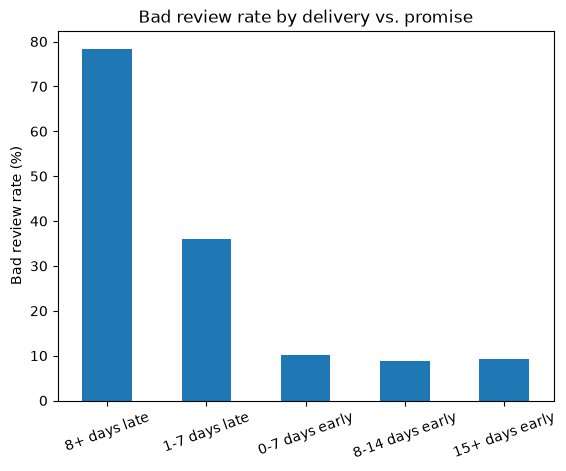

In [36]:
# Bar chart: bad review rate by delivery vs. promise
buffer_rate = data_reviewed.groupby("buffer_group", observed=True)["bad_review"].mean() * 100

buffer_rate.plot(kind="bar")
plt.title("Bad review rate by delivery vs. promise")
plt.ylabel("Bad review rate (%)")
plt.xlabel("")
plt.xticks(rotation=20)
plt.savefig("images/bad_review_by_buffer.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. Other patterns

Orders with several items or several sellers, and how late and bad reviews change over the months.

In [37]:
# Bad review rate by number of items and by number of sellers in the order
print(data_reviewed.groupby("item_count")["bad_review"].agg(["count", "mean"]).head(6))
print(data_reviewed.groupby("seller_count")["bad_review"].agg(["count", "mean"]))

            count      mean
item_count                 
1           86296  0.112682
2            7319  0.253996
3            1286  0.290824
4             487  0.342916
5             193  0.316062
6             186  0.338710
              count      mean
seller_count                 
1             94563  0.123484
2              1202  0.463394
3                54  0.611111
4                 3  1.000000
5                 2  1.000000


In [38]:
# Orders, late rate and bad review rate for each month (year + month)
data_reviewed["year_month"] = data_reviewed["order_purchase_timestamp"].dt.to_period("M")

month_stats = data_reviewed.groupby("year_month").agg(
    orders=("order_id", "count"),
    late_rate=("is_late", "mean"),
    bad_review_rate=("bad_review", "mean"),
)

print(month_stats.round(3))

            orders  late_rate  bad_review_rate
year_month                                    
2016-09          1      1.000            1.000
2016-10        262      0.008            0.164
2016-12          1      0.000            0.000
2017-01        741      0.030            0.120
2017-02       1643      0.028            0.111
2017-03       2527      0.055            0.112
2017-04       2290      0.077            0.129
2017-05       3517      0.034            0.101
2017-06       3111      0.038            0.107
2017-07       3842      0.034            0.099
2017-08       4165      0.033            0.094
2017-09       4118      0.051            0.103
2017-10       4446      0.052            0.111
2017-11       7237      0.141            0.166
2017-12       5461      0.083            0.144
2018-01       7013      0.065            0.137
2018-02       6507      0.159            0.194
2018-03       6948      0.211            0.212
2018-04       6752      0.052            0.118
2018-05      

## 10. Preparing the data for machine learning

**Features:** only information known at the time of purchase. `purchase_month` is NOT used: it mostly shows which period an order is from (for example, February 2017 and February 2018 were very different), and that does not carry over to future orders. Experiment B below tests what happens when it is added back.

**Encoding:** text columns are turned into 0/1 columns (one-hot encoding), because models only understand numbers.

**Split:** 80% of the orders are used for training and 20% for testing.

In [39]:
# Columns the model is allowed to use (all known at the time of purchase)
feature_columns = [
    "estimated_days", "total_price", "total_freight", "item_count",
    "seller_count", "total_weight_g", "same_state",
    "purchase_weekday",
    "category_en", "customer_state", "seller_state",
]

X = data_reviewed[feature_columns]   # the information the model looks at
y = data_reviewed["bad_review"]      # the answer we want to predict

In [40]:
# One-hot encoding: every category becomes its own 0/1 column
text_columns = ["category_en", "customer_state", "seller_state"]

X_encoded = pd.get_dummies(X, columns=text_columns, dtype=int)

print(X_encoded.shape)

(95824, 131)


In [41]:
# Random split: 80% train, 20% test
# stratify=y keeps the same share of bad reviews in both parts
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())

(76659, 131) (19165, 131)
0.1280736769329107 0.12804591703626403


## 11. Models

We start with a "dummy" model as a reference. Because only about 13% of the orders have a bad review, accuracy alone is misleading, so we also look at recall, precision and ROC-AUC.

In [42]:
# Baseline: always predicts "good review"
# Its accuracy is high (about 87%), but it finds no bad reviews at all (recall = 0)
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
dummy_pred = dummy.predict(X_test)

print("Accuracy:", accuracy_score(y_test, dummy_pred))
print("Recall:", recall_score(y_test, dummy_pred))

Accuracy: 0.871954082963736
Recall: 0.0


In [43]:
# Model 1: Logistic Regression (needs scaled data)
# The scaler learns from the training data only, then is applied to the test data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# class_weight="balanced" makes the model pay more attention to the rare bad reviews
log_model = LogisticRegression(max_iter=1000, class_weight="balanced")
log_model.fit(X_train_scaled, y_train)

log_pred = log_model.predict(X_test_scaled)                 # 0 or 1 for each order
log_prob = log_model.predict_proba(X_test_scaled)[:, 1]     # probability of a bad review

print(classification_report(y_test, log_pred))
print("ROC-AUC:", roc_auc_score(y_test, log_prob))

              precision    recall  f1-score   support

           0       0.91      0.68      0.78     16711
           1       0.19      0.52      0.28      2454

    accuracy                           0.66     19165
   macro avg       0.55      0.60      0.53     19165
weighted avg       0.81      0.66      0.71     19165

ROC-AUC: 0.6311540032120916


In [44]:
# Model 2: Random Forest (many decision trees, no scaling needed)
rf_model = RandomForestClassifier(
    n_estimators=200,       # number of trees
    max_depth=12,           # limits how deep each tree can go
    min_samples_leaf=20,    # every leaf needs at least 20 orders (less memorizing)
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,              # use all CPU cores
)
rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, rf_pred))
print("ROC-AUC:", roc_auc_score(y_test, rf_prob))

              precision    recall  f1-score   support

           0       0.91      0.71      0.79     16711
           1       0.20      0.50      0.28      2454

    accuracy                           0.68     19165
   macro avg       0.55      0.60      0.54     19165
weighted avg       0.81      0.68      0.73     19165

ROC-AUC: 0.6386730611975568


In [45]:
# The 10 most important features according to the Random Forest
importances = pd.Series(rf_model.feature_importances_, index=X_train.columns)
print(importances.sort_values(ascending=False).head(10))

item_count           0.230784
total_freight        0.163143
seller_count         0.098929
customer_state_RJ    0.063068
total_weight_g       0.053341
total_price          0.052633
estimated_days       0.049526
customer_state_SP    0.040139
same_state           0.037717
seller_state_SP      0.024448
dtype: float64


In [46]:
# Model 3: Gradient Boosting (trees built one after another, each fixing the previous mistakes)
gb_model = HistGradientBoostingClassifier(
    max_iter=200,           # number of trees
    learning_rate=0.1,
    max_depth=6,
    min_samples_leaf=50,
    class_weight="balanced",
    random_state=42,
)
gb_model.fit(X_train, y_train)

gb_pred = gb_model.predict(X_test)
gb_prob = gb_model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, gb_pred))
print("ROC-AUC:", roc_auc_score(y_test, gb_prob))

              precision    recall  f1-score   support

           0       0.91      0.73      0.81     16711
           1       0.21      0.48      0.29      2454

    accuracy                           0.70     19165
   macro avg       0.56      0.61      0.55     19165
weighted avg       0.82      0.70      0.75     19165

ROC-AUC: 0.6435487105521805


In [47]:
# Comparison table of the three models (random split)
results = pd.DataFrame({
    "model": ["Logistic Regression", "Random Forest", "Gradient Boosting"],
    "roc_auc": [
        roc_auc_score(y_test, log_prob),
        roc_auc_score(y_test, rf_prob),
        roc_auc_score(y_test, gb_prob),
    ],
    "recall": [
        recall_score(y_test, log_pred),
        recall_score(y_test, rf_pred),
        recall_score(y_test, gb_pred),
    ],
    "precision": [
        precision_score(y_test, log_pred),
        precision_score(y_test, rf_pred),
        precision_score(y_test, gb_pred),
    ],
})

print(results.round(3))

                 model  roc_auc  recall  precision
0  Logistic Regression    0.631   0.521      0.192
1        Random Forest    0.639   0.498      0.199
2    Gradient Boosting    0.644   0.485      0.211


## 12. Experiments

All experiments use the Gradient Boosting model with the same settings.

- **Experiment A:** add `is_late` (only known after delivery). This shows an upper limit: how much better could we predict if we knew about the delay in advance?
- **Experiment B:** add `purchase_month` back to see how much it helps.
- **Time-based split:** train on older orders (before June 2018) and test on newer ones. This is closer to real life, because a model must predict future orders.

In [48]:
# Experiment A: add is_late (NOT usable in real life, it is only known after delivery)
X_late = X_encoded.copy()
X_late["is_late"] = data_reviewed["is_late"]

X_train_a, X_test_a, y_train_a, y_test_a = train_test_split(
    X_late, y, test_size=0.2, random_state=42, stratify=y
)

gb_late = HistGradientBoostingClassifier(
    max_iter=200, learning_rate=0.1, max_depth=6,
    min_samples_leaf=50, class_weight="balanced", random_state=42,
)
gb_late.fit(X_train_a, y_train_a)

late_pred = gb_late.predict(X_test_a)
late_prob = gb_late.predict_proba(X_test_a)[:, 1]

print("ROC-AUC:", roc_auc_score(y_test_a, late_prob))
print("Recall:", recall_score(y_test_a, late_pred))
print("Precision:", precision_score(y_test_a, late_pred))

ROC-AUC: 0.7455746564992864
Recall: 0.532599837000815
Precision: 0.38622931442080377


In [49]:
# Experiment B: add purchase_month back
X_month = X_encoded.copy()
X_month["purchase_month"] = data_reviewed["purchase_month"]

X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(
    X_month, y, test_size=0.2, random_state=42, stratify=y
)

gb_month = HistGradientBoostingClassifier(
    max_iter=200, learning_rate=0.1, max_depth=6,
    min_samples_leaf=50, class_weight="balanced", random_state=42,
)
gb_month.fit(X_train_b, y_train_b)

month_pred = gb_month.predict(X_test_b)
month_prob = gb_month.predict_proba(X_test_b)[:, 1]

print("ROC-AUC:", roc_auc_score(y_test_b, month_prob))
print("Recall:", recall_score(y_test_b, month_pred))
print("Precision:", precision_score(y_test_b, month_pred))

ROC-AUC: 0.6580773138561451
Recall: 0.4930725346373268
Precision: 0.22834497074919796


In [50]:
# Time-based split: orders before 1 June 2018 for training, orders from 1 June 2018 for testing
cutoff = pd.Timestamp("2018-06-01")
is_train = data_reviewed["order_purchase_timestamp"] < cutoff   # True = training order

X_train_t = X_encoded[is_train]
X_test_t = X_encoded[~is_train]     # ~ means "the opposite"
y_train_t = y[is_train]
y_test_t = y[~is_train]

print(len(X_train_t), len(X_test_t))
print(y_train_t.mean(), y_test_t.mean())   # the test period has fewer bad reviews

77304 18520
0.13543930456380007 0.09730021598272139


In [51]:
# Gradient Boosting trained on older orders, tested on newer orders
gb_time = HistGradientBoostingClassifier(
    max_iter=200, learning_rate=0.1, max_depth=6,
    min_samples_leaf=50, class_weight="balanced", random_state=42,
)
gb_time.fit(X_train_t, y_train_t)

time_pred = gb_time.predict(X_test_t)
time_prob = gb_time.predict_proba(X_test_t)[:, 1]

# Compare precision with the bad review rate of the test period, not with the random split
print("ROC-AUC:", roc_auc_score(y_test_t, time_prob))
print("Recall:", recall_score(y_test_t, time_pred))
print("Precision:", precision_score(y_test_t, time_pred))

ROC-AUC: 0.588449196895316
Recall: 0.45615982241953384
Precision: 0.13230323515210043


In [52]:
# If we check only the 10% riskiest orders, how many bad reviews do we find?
test_results = pd.DataFrame({"actual": y_test_t.values, "risk": time_prob})
test_results = test_results.sort_values("risk", ascending=False)

top_n = int(len(test_results) * 0.1)
top = test_results.head(top_n)

print("Orders in top 10%:", top_n)
print("Bad review rate in top 10%:", top["actual"].mean())
print("Share of all bad reviews captured:", top["actual"].sum() / test_results["actual"].sum())

Orders in top 10%: 1852
Bad review rate in top 10%: 0.19978401727861772
Share of all bad reviews captured: 0.20532741398446172


In [72]:
# Logistic Regression and Random Forest on the time-based split
# (Gradient Boosting was already trained on it: time_prob)
scaler_t = StandardScaler()
X_train_t_scaled = scaler_t.fit_transform(X_train_t)
X_test_t_scaled = scaler_t.transform(X_test_t)

log_time = LogisticRegression(max_iter=1000, class_weight="balanced")
log_time.fit(X_train_t_scaled, y_train_t)
log_time_prob = log_time.predict_proba(X_test_t_scaled)[:, 1]

rf_time = RandomForestClassifier(
    n_estimators=200, max_depth=12, min_samples_leaf=20,
    class_weight="balanced", random_state=42, n_jobs=-1,
)
rf_time.fit(X_train_t, y_train_t)
rf_time_prob = rf_time.predict_proba(X_test_t)[:, 1]

# Comparison table: random split vs time-based split
model_results = pd.DataFrame({
    "model": ["Logistic Regression", "Random Forest", "Gradient Boosting"],
    "roc_auc_random_split": [
        roc_auc_score(y_test, log_prob),
        roc_auc_score(y_test, rf_prob),
        roc_auc_score(y_test, gb_prob),
    ],
    "roc_auc_time_split": [
        roc_auc_score(y_test_t, log_time_prob),
        roc_auc_score(y_test_t, rf_time_prob),
        roc_auc_score(y_test_t, time_prob),
    ],
})
print(model_results.round(3))

                 model  roc_auc_random_split  roc_auc_time_split
0  Logistic Regression                 0.631               0.589
1        Random Forest                 0.639               0.589
2    Gradient Boosting                 0.644               0.588


### Risk groups and a simple rule

We split the test-period orders (June-August 2018) into 5 equal groups by the model's risk score, and compare the model with a one-line rule: "the order has several items or several sellers".

In [ ]:
# Test-period orders (June-August 2018) with the model's risk score
test_orders = data_reviewed.loc[~is_train, ["order_id", "bad_review", "is_late", "item_count", "seller_count"]].copy()
test_orders["risk_score"] = time_prob     # Gradient Boosting, trained on older orders

# multi = 1 if the order has several items or several sellers (the simple rule)
test_orders["multi"] = ((test_orders["item_count"] > 1) | (test_orders["seller_count"] > 1)).astype(int)

# Split the orders into 5 equal groups by risk score (1 = lowest risk, 5 = highest risk)
test_orders["risk_group"] = pd.qcut(
    test_orders["risk_score"], 5,
    labels=["1 (lowest)", "2", "3", "4", "5 (highest)"],
)

# For each group: number of orders, real bad review rate, late rate
risk_table = test_orders.groupby("risk_group", observed=True).agg(
    orders=("order_id", "count"),
    bad_review_rate=("bad_review", "mean"),
    late_rate=("is_late", "mean"),
).reset_index()

print(risk_table.round(3))

# Share of orders with several items or sellers in each risk group
print(test_orders.groupby("risk_group", observed=True)["multi"].mean().round(3))

In [ ]:
# Compare the simple rule with the model (test period)
n_test = len(test_orders)
total_bad = test_orders["bad_review"].sum()

rule_group = test_orders[test_orders["multi"] == 1]
top10 = test_orders.sort_values("risk_score", ascending=False).head(int(n_test * 0.1))
top20 = test_orders[test_orders["risk_group"] == "5 (highest)"]

comparison = pd.DataFrame({
    "method": ["Simple rule: several items or sellers", "Model: riskiest 10%", "Model: riskiest 20%"],
    "orders_flagged": [len(rule_group), len(top10), len(top20)],
    "bad_review_rate": [
        rule_group["bad_review"].mean(),
        top10["bad_review"].mean(),
        top20["bad_review"].mean(),
    ],
    "share_of_bad_reviews_found": [
        rule_group["bad_review"].sum() / total_bad,
        top10["bad_review"].sum() / total_bad,
        top20["bad_review"].sum() / total_bad,
    ],
})

print(comparison.round(3))
print("Overall bad review rate in the test period:", round(test_orders["bad_review"].mean(), 3))

# Save both tables for Power BI
os.makedirs("powerbi", exist_ok=True)
risk_table.to_csv("powerbi/risk_groups.csv", index=False)
comparison.to_csv("powerbi/rule_vs_model.csv", index=False)

## 13. What do the review messages say?

About 41% of the reviews have a written message (in Portuguese). We clean the text, look at the most common words, and group the bad-review messages into reasons with simple keyword matching. The result is approximate: a message can mention more than one reason, and some messages match no reason.

In [53]:
# Add the review text to our orders (we keep our data_reviewed table unchanged)
text_data = data_reviewed[["order_id", "bad_review", "is_late"]].merge(
    reviews_clean[["order_id", "review_comment_message"]],
    on="order_id",
    how="left",
)

In [ ]:
text_data.head()

In [55]:
# Keep only the orders where the customer wrote a message
text_data = text_data[text_data["review_comment_message"].notnull()].copy()

In [56]:
print(len(text_data))                         # orders with a message
print(text_data["bad_review"].mean())         # share of bad reviews among them
print(text_data["bad_review"].sum() / data_reviewed["bad_review"].sum())   # share of all bad reviews that have a message

38898
0.23739009717723275
0.752444589308996


In [ ]:
text_data["text"] = (
    text_data["review_comment_message"]
    .str.lower()                              # all letters to lowercase
    .str.normalize("NFKD")                    # split letters from their accents (ã becomes a + ~)
    .str.encode("ascii", errors="ignore")     # drop everything that is not plain ASCII (the accents)
    .str.decode("utf-8")                      # back to normal text
    .str.replace(r"[^a-z\s]", " ", regex=True)   # replace punctuation and digits with a space
)

print(text_data[["review_comment_message", "text"]].head(3))

In [58]:
bad_text = text_data[text_data["bad_review"] == 1]["text"]

words = bad_text.str.split().explode()      # one word per row
words = words[words.str.len() > 3]          # skip very short words (de, a, o, ...)

print(words.value_counts().head(40))

text
produto       5106
recebi        2784
comprei       1699
veio          1510
para          1360
ainda         1154
entregue      1138
entrega       1115
chegou        1038
estou          797
muito          775
prazo          736
compra         669
mais           641
esta           641
pedido         625
loja           615
como           599
agora          533
apenas         521
minha          500
dois           472
produtos       466
porem          451
pois           436
qualidade      432
lannister      430
nada           429
site           429
quero          413
outro          401
mesmo          399
contato        382
aguardando     343
tive           330
dias           322
duas           316
correios       309
momento        308
diferente      308
Name: count, dtype: int64


In [65]:
categories = {
    "not_received": [
        "nao recebi", "nao chegou", "nao chegaram", "nao foi entregue", "nao foram entregues",
        "nao entregue", "nao entregaram", "nao entregou", "ainda nao", "nada do",
        "ate o momento", "ate agora", "quando vai chegar", "quando chega",
    ],
    "partial_delivery": [
        "so entregaram", "so veio", "so chegou", "so recebi", "somente", "apenas",
        "faltou", "faltando", "incompleto",
    ],
    "delay": ["atraso", "atrasou", "atrasado", "demora", "demorou", "prazo", "nao cumpriu", "combinado"],
    "carrier": ["transportadora", "entregador", "correios"],
    "product_problem": [
        "defeito", "quebrado", "quebrou", "danificado", "nao funciona", "qualidade",
        "nao reconhecido", "nao liga", "compativel", "nao serve",
    ],
    "wrong_item": ["errado", "diferente", "outro produto"],
    "seller_or_service": ["vendedor", "atendimento", "reembolso", "devolucao", "cancel", "troca"],
}

# 1 if the message contains at least one keyword of the category, otherwise 0
for name, keywords in categories.items():
    pattern = "|".join(keywords)
    text_data[name] = text_data["text"].str.contains(pattern).astype(int)

bad = text_data[text_data["bad_review"] == 1]
category_names = list(categories.keys())

print(bad[category_names].mean().round(3).sort_values(ascending=False))
print("No category matched:", round((bad[category_names].sum(axis=1) == 0).mean(), 3))
print(bad.groupby("is_late")[category_names].mean().round(3).T)

not_received         0.298
partial_delivery     0.150
delay                0.130
seller_or_service    0.108
product_problem      0.104
wrong_item           0.070
carrier              0.035
dtype: float64
No category matched: 0.306
is_late                0      1
not_received       0.178  0.566
partial_delivery   0.202  0.034
delay              0.080  0.243
carrier            0.024  0.059
product_problem    0.141  0.019
wrong_item         0.095  0.016
seller_or_service  0.126  0.067


In [66]:
bad = text_data[text_data["bad_review"] == 1]
category_names = list(categories.keys())

# Share of bad-review messages that mention each category
print(bad[category_names].mean().round(3).sort_values(ascending=False))

# Share of bad-review messages that match no category at all
print("No category matched:", round((bad[category_names].sum(axis=1) == 0).mean(), 3))

# Same shares, separately for late (1) and on-time (0) orders
print(bad.groupby("is_late")[category_names].mean().round(3))
print(bad["is_late"].value_counts())

not_received         0.298
partial_delivery     0.150
delay                0.130
seller_or_service    0.108
product_problem      0.104
wrong_item           0.070
carrier              0.035
dtype: float64
No category matched: 0.306
         not_received  partial_delivery  delay  carrier  product_problem  \
is_late                                                                    
0               0.178             0.202  0.080    0.024            0.141   
1               0.566             0.034  0.243    0.059            0.019   

         wrong_item  seller_or_service  
is_late                                 
0             0.095              0.126  
1             0.016              0.067  
is_late
0    6370
1    2864
Name: count, dtype: int64


In [ ]:
# 10 random messages: on-time orders with a bad review, flagged as "product_problem"
sample = bad[(bad["is_late"] == 0) & (bad["product_problem"] == 1)]["review_comment_message"]

for t in sample.sample(min(10, len(sample)), random_state=1):
    print("-", t)

In [ ]:
# 15 random bad-review messages that no category matched
unmatched = bad[bad[category_names].sum(axis=1) == 0]["review_comment_message"]

for t in unmatched.sample(15, random_state=1):
    print("-", t)

In [69]:
# Does "not received" appear more often in orders with several items or sellers?
bad_extra = bad.merge(
    data_reviewed[["order_id", "item_count", "seller_count"]],
    on="order_id",
    how="left",
)

# multi = 1 if the order has more than one item or more than one seller
bad_extra["multi"] = ((bad_extra["item_count"] > 1) | (bad_extra["seller_count"] > 1)).astype(int)

print(bad_extra.groupby(["is_late", "multi"])["not_received"].agg(["count", "mean"]).round(3))

               count   mean
is_late multi              
0       0       4476  0.145
        1       1894  0.255
1       0       2598  0.576
        1        266  0.462


### Numbers for the flow diagram and a check of the "partial delivery" reason

In [70]:
# Numbers for the flow diagram
print("All orders:", len(orders))
print("Delivered (with delivery date):", len(delivered))
print("Delivered with a review:", len(data_reviewed))
print("With a written message:", len(text_data))
print("All bad reviews:", data_reviewed["bad_review"].sum())
print("Bad reviews with a message:", len(bad))
print("  of which late orders:", bad["is_late"].sum())
print("  of which on-time orders:", (bad["is_late"] == 0).sum())

All orders: 99441
Delivered (with delivery date): 96470
Delivered with a review: 95824
With a written message: 38898
All bad reviews: 12272
Bad reviews with a message: 9234
  of which late orders: 2864
  of which on-time orders: 6370


In [71]:
# Is "partial_delivery" really more common in orders with several items or sellers?
bad_extra = bad.merge(
    data_reviewed[["order_id", "item_count", "seller_count"]],
    on="order_id",
    how="left",
)
bad_extra["multi"] = ((bad_extra["item_count"] > 1) | (bad_extra["seller_count"] > 1)).astype(int)

print(bad_extra.groupby(["is_late", "multi"])["partial_delivery"].agg(["count", "mean"]).round(3))

               count   mean
is_late multi              
0       0       4476  0.061
        1       1894  0.535
1       0       2598  0.018
        1        266  0.184


## 14. Export for Power BI

The tables for the dashboard are saved as CSV files in the `powerbi` folder: one row per order, one row per state, the model results, the review-message reasons and the numbers for the flow diagram. (The risk-group and simple-rule tables were saved in section 12.)

In [73]:
# Create the folder for the Power BI files (if it does not exist yet)
os.makedirs("powerbi", exist_ok=True)

# ---- File 1: one row per order
export_orders = data_reviewed[[
    "order_id", "order_purchase_timestamp", "customer_state", "seller_state",
    "category_en", "total_price", "total_freight", "item_count", "seller_count",
    "estimated_days", "delivery_days", "is_late", "buffer_days", "buffer_group",
    "delivery_group", "review_score", "bad_review",
]].copy()

export_orders["purchase_date"] = export_orders["order_purchase_timestamp"].dt.date
export_orders = export_orders.drop(columns=["order_purchase_timestamp"])

# Add the review-text categories (orders without a message get 0)
text_flags = text_data[["order_id"] + category_names].copy()
text_flags["has_message"] = 1
export_orders = export_orders.merge(text_flags, on="order_id", how="left")

fill_columns = category_names + ["has_message"]
export_orders[fill_columns] = export_orders[fill_columns].fillna(0).astype(int)

# Add the model's risk score (only for the test period: June-August 2018)
risk = pd.DataFrame({
    "order_id": data_reviewed.loc[~is_train, "order_id"].values,
    "risk_score": time_prob,
})
export_orders = export_orders.merge(risk, on="order_id", how="left")
export_orders["in_test_period"] = export_orders["risk_score"].notnull().astype(int)

export_orders.to_csv("powerbi/orders_for_powerbi.csv", index=False)

# ---- File 2: one row per state
state_export = state_stats.join(
    state_time[["avg_estimated_days", "avg_delivery_days", "promise_buffer"]]
)
state_export.reset_index().to_csv("powerbi/states_for_powerbi.csv", index=False)

# ---- File 3: model results
model_results.to_csv("powerbi/model_results.csv", index=False)

# ---- File 4: what bad-review messages say (late vs on-time orders)
text_summary = bad.groupby("is_late")[category_names].mean().round(4).T
text_summary.columns = ["on_time_orders", "late_orders"]
text_summary = text_summary.reset_index().rename(columns={"index": "category"})
text_summary.to_csv("powerbi/text_categories.csv", index=False)

# ---- File 5: numbers for the flow diagram
funnel = pd.DataFrame({
    "step": [
        "All orders", "Delivered (with date)", "Delivered with a review",
        "With a written message", "Bad reviews with a message",
        "Late orders", "On-time orders",
    ],
    "orders": [
        len(orders), len(delivered), len(data_reviewed),
        len(text_data), len(bad),
        bad["is_late"].sum(), (bad["is_late"] == 0).sum(),
    ],
})
funnel.to_csv("powerbi/funnel.csv", index=False)

# Check what was created
print(os.listdir("powerbi"))
print(export_orders.shape)
print(export_orders["in_test_period"].sum())
print(funnel)

['funnel.csv', 'model_results.csv', 'orders_for_powerbi.csv', 'states_for_powerbi.csv', 'text_categories.csv']
(95824, 27)
18520
                         step  orders
0                  All orders   99441
1       Delivered (with date)   96470
2     Delivered with a review   95824
3      With a written message   38898
4  Bad reviews with a message    9234
5                 Late orders    2864
6              On-time orders    6370


## 15. Key findings and limitations

**What drives bad reviews**
- Late delivery is the strongest single signal. Late orders have an average review score of 2.6 (on-time orders: 4.3), and 54% of them get a bad review (1-2 stars), against 9% of on-time orders.
- Even so, late delivery explains only about a third of all bad reviews. About two thirds (roughly 8,100 of 12,300) come from orders that arrived on time.
- Both the waiting time and the broken promise matter, and the broken promise matters more. From 8 days of waiting on, late orders get about three times as many bad reviews as on-time orders with the same delivery time. Arriving earlier than promised does not help: the bad review rate is about 9-10% for all orders that arrive on time or early.
- Orders with several items or sellers are about 10% of all orders, but they have a much higher bad review rate: 25-34% for orders with 2-4 items (11% for one item), and 46% for orders with two sellers (12% for one seller). About half of the bad reviews of such orders that arrived on time say that only part of the order arrived.
- States where Olist promises a small time buffer have the most late deliveries (for example Alagoas 23%, Maranhao 19%, Sergipe 15%). Across the 24 states with 100+ orders, a smaller buffer goes with a higher late rate (correlation about -0.73).

**What the review messages say** (38,898 of 95,824 reviews have a message, and 75% of the bad reviews have one)
- Bad reviews of late orders: 57% say the order did not arrive and 24% mention delay or a broken promise.
- Bad reviews of on-time orders are more varied: only part of the order arrived (20%), order did not arrive (18%), product problem (14%), seller or service (13%).
- The reasons come from keyword matching on Portuguese text, so they are approximate. About 31% of the bad-review messages match no reason.

**Models**
- A model that always says "good review" is right 87% of the time but finds no bad reviews, so we look at ROC-AUC and recall.
- Logistic Regression, Random Forest and Gradient Boosting reach a ROC-AUC of 0.63-0.64 on a random split and 0.59 on newer orders (June-August 2018). The more complex models do not help: the limit is the information in the data, not the algorithm.
- Adding late-delivery information (not known at purchase time) raises the ROC-AUC to 0.75. Most of the missing information is whether the order will arrive late.
- Adding the purchase month raises the ROC-AUC to 0.66, but it is not used. It mostly marks the period (February 2017 and February 2018 were very different), and that does not carry over to future orders.
- In the test period, the riskiest 20% of orders have a 15.9% bad review rate, against 7.5% in the lowest group and 9.7% overall, and they hold about a third of all bad reviews. The other four groups are hard to tell apart.
- A simple rule works about as well as the models: orders with several items or sellers (9.5% of the test orders) have a 23.5% bad review rate and hold 22.8% of all bad reviews, slightly more than the model's riskiest 10% (20.0% and 20.5%). The model finds more bad reviews only by flagging more orders, and its risk score does not follow late delivery.

**Limitations**
- Only delivered orders with a review are used (about 95.8k of 99.4k orders). Canceled orders and customers who did not write a review are not included.
- For orders with several items or sellers, the category and the seller state come from the first item only.
- Distances are straight lines to the state capital, not real road distances.
- The data does not show whether a larger delivery-promise buffer would reduce sales. Longer promises can reduce late deliveries, but we cannot measure the effect on sales.
- The data has no information about product quality, damaged items or seller communication, so it cannot explain most bad reviews of on-time orders.
- Customers who write a message may differ from those who do not, and the keyword matching is approximate.
- In the time-based split, the test period is June-August 2018, and August 2018 is the last month of the data.